# Análisis exploratorio de datos (EDA)

Explora la estructura, distribución de etiquetas y características del dataset GoEmotions.

In [ ]:
import sys; sys.path.append("..")  # Importa sys y agrega la carpeta padre ("..") a la ruta de búsqueda de módulos para poder importar paquetes del proyecto.
import pandas as pd  # Importa pandas bajo el alias pd para trabajar con estructuras de datos tabulares (como DataFrames)[cite: 1].
from src.preprocessing import *  # Importa todos los objetos públicos (funciones, clases o constantes) del módulo src/preprocessing.py al espacio de nombres actual[cite: 1].
from src.visualize import *  # Importa todos los objetos públicos del módulo src/visualize.py (como las funciones de gráficas que revisamos antes) al espacio de nombres actual[cite: 1].

In [ ]:
from src.visualize import plot_class_balance, plot_length_distribution, plot_top_words  # Importa específicamente esas tres funciones de visualización desde el módulo src/visualize.py al espacio de nombres actual.

## 1. Carga y filtrado
Los CSV crudos tienen una fila por evaluador. Se agrupa por comentario y se conserva una emoción solo si al menos 2 evaluadores la marcaron.

In [ ]:
raw = load_raw()  # Llama a la función load_raw() (de preprocessing) para cargar los datos sin procesar y guarda el resultado en `raw`.
agreed = aggregate_filtered(raw)  # Aplica aggregate_filtered() a los datos crudos para agrupar/filtrar anotaciones o registros según acuerdo y guarda en `agreed`.
filtered = assign_sentiment(agreed)  # Asigna etiquetas de sentimiento/clase a los datos agregados y guarda el DataFrame resultante en `filtered`[cite: 1].

print("Filas crudas:", len(raw))  # Imprime el número total de filas que tiene el DataFrame inicial `raw`[cite: 1].
print("Comentarios únicos:", raw["id"].nunique())  # Calcula cuántos valores distintos hay en la columna "id" de `raw` (comentarios únicos) y lo imprime[cite: 1].
print("Tras filtro de acuerdo:", len(filtered))  # Imprime la cantidad de registros que quedaron después del filtrado y asignación de sentimiento en `filtered`[cite: 1].
filtered["group"].value_counts()  # Cuenta cuántos registros hay por cada categoría/clase en la columna "group" de `filtered` (y al ir al final de la celda, lo muestra como salida)[cite: 1].

Filas crudas: 211225
Comentarios únicos: 58011
Tras filtro de acuerdo: 54263


group
positive     19020
neutral      16021
negative     10217
ambiguous     4805
mixed         4200
Name: count, dtype: int64

## 2. Dataset balanceado (500 positivos + 500 negativos)

In [ ]:
balanced = build_balanced(filtered)  # Llama a build_balanced() sobre `filtered` para crear un subconjunto balanceado entre clases y lo guarda en `balanced`.
balanced["clean"] = balanced["text"].apply(clean_text)  # Aplica la función clean_text() a cada texto en la columna "text" y guarda el resultado limpio en la nueva columna "clean"[cite: 1].
balanced["n_words"] = balanced["text"].str.split().str.len()      # texto original  # Separa el texto original por espacios y guarda el número de palabras en la columna "n_words"[cite: 1].
balanced["n_tokens"] = balanced["clean"].str.split().str.len()    # tras la limpieza  # Separa el texto limpio por espacios y guarda el número de tokens/palabras resultantes en "n_tokens"[cite: 1].
balanced.head()  # Muestra las primeras 5 filas del DataFrame `balanced` para inspeccionar las columnas creadas[cite: 1].

,id,text,group,label,clean,n_words,n_tokens
0,eedoc1z,Very sorry for your loss.,negative,0,sorry loss,5,2
1,edawyul,The more you wind me up the worse it gets for ...,negative,0,wind worse gets later,14,4
2,eeoyj9s,AYY! Anti-Semitism! Didn't expect that from An...,negative,0,ayy anti semitism didn't expect ancaps not sur...,11,8
3,ef1cgbq,no the first part about UK becoming a failed s...,negative,0,no first part uk becoming failed state think l...,24,14
4,ef4jhpr,i hope this grossed u out ur welcome 😎,positive,1,hope grossed u ur welcome,9,5


## 3. Balance de clases

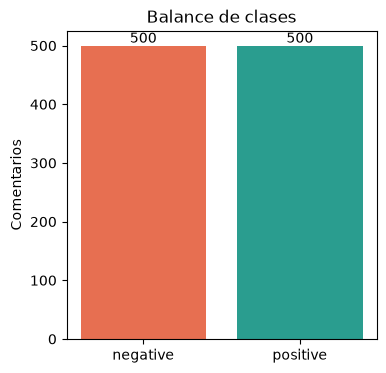

In [ ]:
plot_class_balance(balanced);  # Llama a plot_class_balance() pasando el DataFrame `balanced` para generar y guardar la gráfica del balance de clases en outputs/figures/ (el punto y coma final evita que se imprima la representación textual del objeto figura en la salida de la celda).

## 4. Distribución de la longitud

group           negative  positive
n_words  count    500.00    500.00
         mean      13.69     12.68
         std        6.58      6.48
         min        2.00      1.00
         25%        8.00      7.00
         50%       14.00     12.00
         75%       19.00     18.00
         max       29.00     29.00
n_tokens count    500.00    500.00
         mean       7.50      6.82
         std        3.70      3.61
         min        1.00      1.00
         25%        4.00      4.00
         50%        7.00      6.50
         75%       10.00      9.00
         max       21.00     18.00


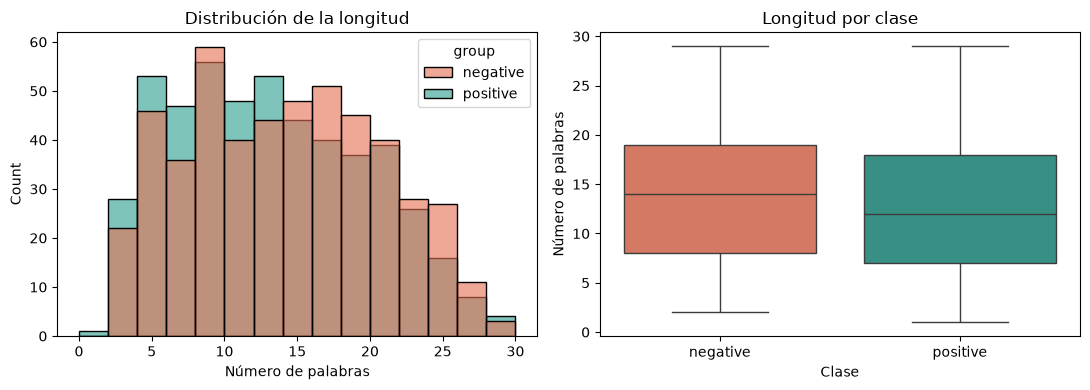

In [ ]:
print(balanced.groupby("group")[["n_words", "n_tokens"]].describe().round(2).T)  # Agrupa `balanced` por "group", calcula estadísticas descriptivas (conteo, media, desv. est., mín., cuartiles, máx.) de `n_words` y `n_tokens`, redondea a 2 decimales, transpón la tabla (`.T`) para leer métricas en filas y clases en columnas, y la imprime.
plot_length_distribution(balanced);  # Llama a plot_length_distribution() con `balanced` para generar el histograma y el boxplot de longitud por clase, guardarlo en `outputs/figures/` y suprimir (`;`) la salida textual de la figura.

## 5. Palabras más frecuentes por clase

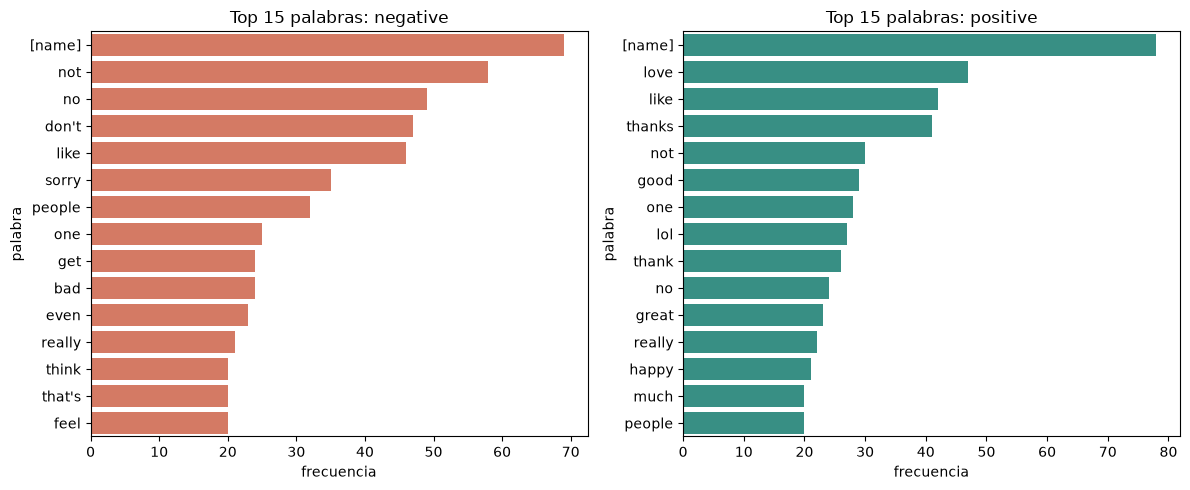

In [ ]:
plot_top_words(balanced);  # Llama a plot_top_words() usando el DataFrame `balanced` (con sus valores por defecto: `text_col="clean"`, `k=15` y `name="eda_top_words.png"`) para graficar las 15 palabras más frecuentes en `"negative"` y en `"positive"`, guardar la figura en `outputs/figures/` y suprimir (`;`) la salida textual del objeto figura.

## 6. Split train/test y guardado

In [8]:
train, test = split_data(balanced)
print(len(train), len(test))
print(train["label"].value_counts().to_dict(), test["label"].value_counts().to_dict())

balanced.to_csv("../data/processed/balanced_1000.csv", index=False)
train.to_csv("../data/processed/train.csv", index=False)
test.to_csv("../data/processed/test.csv", index=False)

800 200
{1: 400, 0: 400} {1: 100, 0: 100}
